# Imputation
The aim of this notebook is to show how the different imputation strategies provided in the `renewal-modeling` package can be used. We will first import the required packages, and then set up a mock dataset to be used in the notebook.

In [121]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pywearable.processing.imputation as imputation

## Set up dataset
So, let's assume that our dataset is composed of only three users (`"user-01"`, `"user-02"`, and `"user-03"`). For each of these users, we have 30 days of data. We consider only a single **feature** (steps), and we randomly set some values of the features as missing, in order to show how the imputation strategies work. 

For `"user-02"`, we force the data on the first day to be missing so that we can show how to approach missing values in the first days during the imputation part.

In [122]:
# Just creating an index using the from_product
index = pd.MultiIndex.from_product((['user-01','user-02','user-03'],
                                    pd.date_range(
                                        pd.Timestamp.today().normalize(), 
                                        periods=30, 
                                        freq="d")
                                    ),
                                names=['user','date'])
# Create dataset
dataset = pd.DataFrame(index=index).reset_index()
# Randomly generate steps with different distributions across users
steps = []
for user in range(len(dataset["user"].unique())):
    min = np.random.default_rng().random()*5000
    max = 5000 + np.random.default_rng().random()*10000
    steps = np.concatenate((steps, np.random.randint(min, max,30)))


dataset["steps"] = steps#np.random.randint(1000,20000,len(dataset))
# Set up some missing values
dataset.loc[dataset.sample(30).index, "steps"] = np.nan
dataset.loc[(dataset["user"]=="user-02") & (dataset["date"]==pd.Timestamp.today().normalize()),"steps"] = np.nan
dataset.sample(5)

,user,date,steps
88,user-03,2026-03-13,NaN
17,user-01,2026-03-02,NaN
78,user-03,2026-03-03,NaN
52,user-02,2026-03-07,6639.0
71,user-03,2026-02-24,NaN


## Imputation
First, let's set some utility functions to plot values. We will re-use it multiple times throughout the notebook.

In [123]:
def plot_population_value(dataset: pd.DataFrame, ax, strategy="mean"):
    ax.hlines(dataset["steps"].apply(strategy),
                            dataset["date"].min(), 
                            dataset["date"].max(), 
                            "tab:orange",
                            '--' if strategy == "mean" else "-",
                            alpha=0.4, 
                            label=f"Population {strategy}")

In [124]:
def plot_raw_steps_data(dataset, strategy=None, plot_user_mean: bool = True, plot_user_median: bool = True, plot_population_mean: bool = False, plot_population_median: bool = False):
    
    fig, ax = plt.subplots(1,3,figsize=(13,2), sharex=True, sharey=True)
    plt.subplots_adjust(wspace=0.1)
    stats = []
    if plot_user_mean:
        stats.append("mean")
    if plot_user_median:
        stats.append("median")
    for idx, user in enumerate(["user-01", "user-02", "user-03"]):
        user_data = dataset[dataset["user"]==user]
        ax[idx].bar(user_data["date"], user_data["steps"])
        ax[idx].set_title(user, fontweight="bold")
        for stat in stats:
            ax[idx].hlines(user_data["steps"].apply(stat),
                            user_data["date"].min(), 
                            user_data["date"].max(), 
                            "tab:blue",
                            '--' if "mean" in stat else "-", 
                            alpha=0.4, 
                            #color="tab:blue", 
                            label=strategy)
        if plot_population_mean:
            plot_population_value(dataset=dataset, ax=ax[idx])

        if plot_population_median:
            plot_population_value(dataset=dataset, ax=ax[idx], strategy="median")

        if not strategy is None:
            ax[idx].bar(user_data.loc[user_data["steps"].isna(),"date"], 
                user_data.loc[user_data["steps"].isna(),f"steps_{strategy}"],
                label="Imputed", color="tab:orange", alpha=0.4)
            if strategy == "mean_rolling":
                ax[idx].plot(user_data["date"],
                             user_data["steps_rolling_mean"], 
                               linestyle='--', 
                               alpha=0.4, 
                               color="tab:green", 
                               linewidth=2,
                               label=strategy)
            elif strategy == "median_rolling":
                ax[idx].plot(user_data["date"],
                             user_data["steps_rolling_median"], 
                               linestyle='-', 
                               alpha=0.4, 
                               color="tab:green", 
                               linewidth=2,
                               label=strategy)
        ax[idx].set_xlabel("Day", fontweight="bold")
    
    ax[0].xaxis.set_major_locator(mdates.DayLocator(interval=4))
    ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax[0].set_ylabel("Steps", fontweight="bold")
    
    
    return fig, ax

The figure below shows the daily steps value, together with mean (dashed lines) and median values (solid lines) for each user.

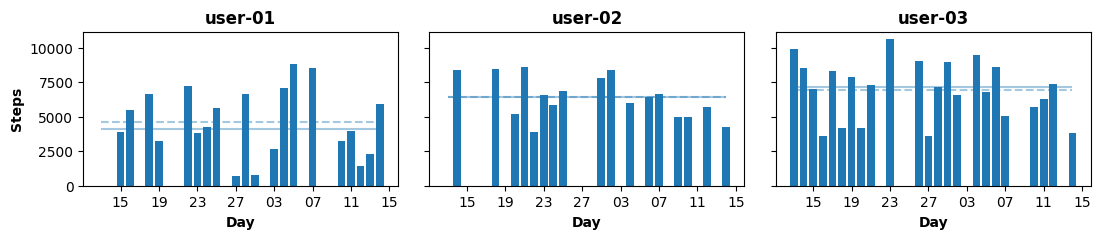

In [125]:
fig, ax = plot_raw_steps_data(dataset=dataset, plot_user_median=True, plot_population_mean=False, plot_population_median=False)

## Mean imputation
The basic imputation strategy is based on the replacement of the values with the mean. 

This can be achieved by calling the function ``renmodeling.processing.imputation.impute_missing_values_with_personalized_mean``.

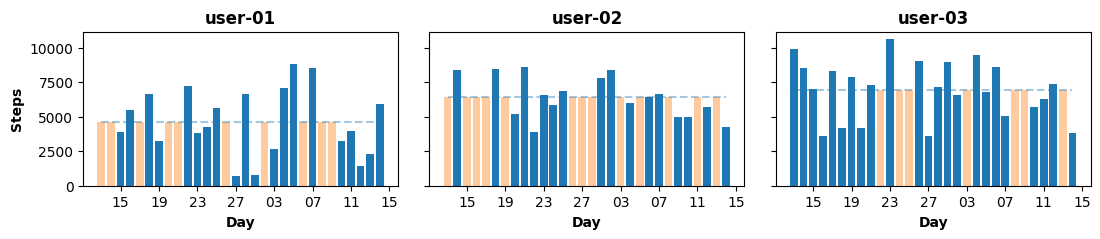

In [126]:
imputed_dataset = imputation.impute_missing_values_with_personalized_mean(
                                                                            dataset=dataset, 
                                                                            on="steps",
                                                                            id_col="user",
                                                                        )
fig, ax = plot_raw_steps_data(dataset=imputed_dataset, 
                              strategy="mean", 
                              plot_user_mean=True,
                              plot_user_median=False)

In the figure above, we can see that the missing values (now shown in orange) were replaced using the mean value personalized for each user. So, the orange bars reach the dashed line for each user. Another option that we have for the imputation with the mean is to use the mean value for the whole population. We can easily do it with ``renmodeling.processing.imputation.impute_missing_values_with_personalized_median``.

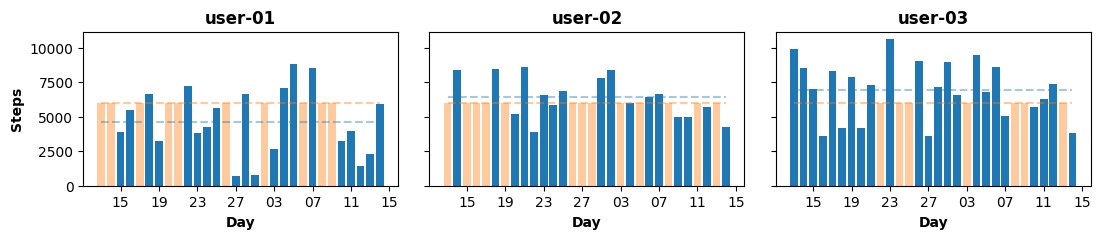

In [127]:
imputed_dataset = imputation.impute_missing_values_with_population_mean(
                                                                        dataset=dataset, 
                                                                        on="steps",
                                                                        )
fig, ax = plot_raw_steps_data(dataset=imputed_dataset, 
                              strategy="mean", 
                              plot_user_mean=True,
                              plot_user_median=False,
                              plot_population_mean=True)

We can see that the imputed values now are equal across all users, and they are set to the population mean value (orange dashed line) and not to the personalized mean (blue dashed line).

## Median Imputation
Similar to the mean imputation, the other option is to have the imputation with the median values.

This can be achieved by calling the function ``renmodeling.processing.imputation.impute_missing_values_with_personalized_median``.

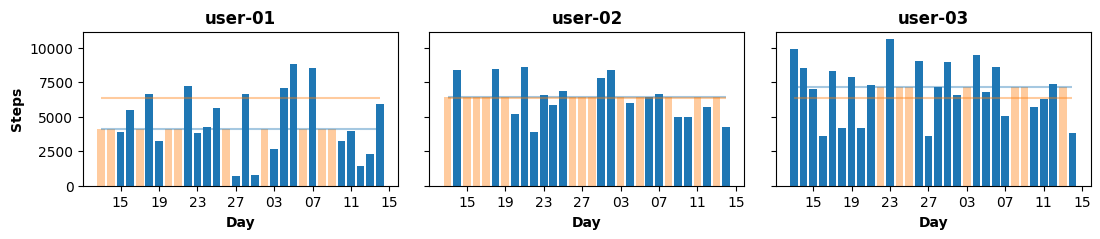

In [128]:
imputed_dataset = imputation.impute_missing_values_with_personalized_median(
                                                                            dataset=dataset, 
                                                                            on="steps",
                                                                            id_col="user"
                                                                            )
fig, ax = plot_raw_steps_data(dataset=imputed_dataset, strategy="median", plot_user_mean=False, plot_population_median=True)

Similarly to the process with the mean imputation, we can use the median population value to perform the imputation of missing values.

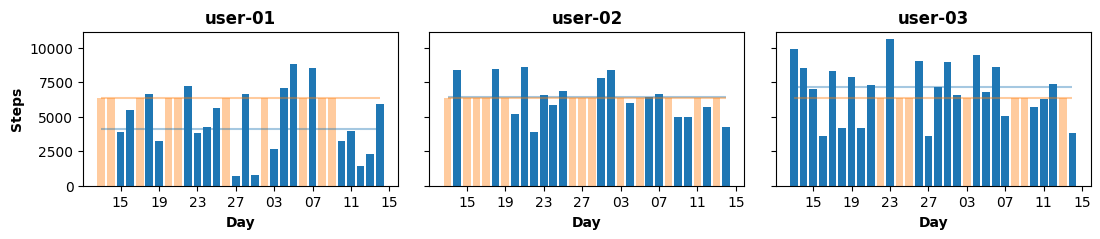

In [129]:
imputed_dataset = imputation.impute_missing_values_with_population_median(
                                                                            dataset=dataset, 
                                                                            on="steps"
                                                                        )
fig, ax = plot_raw_steps_data(dataset=imputed_dataset, strategy="median", plot_user_mean=False, plot_population_median=True)

## Rolling Mean
In addition to the mean and median imputation, we can also perform an imputation with a rolling mean. The purpose of the rolling mean is to impute the value with the mean value computed on the previously

With the rolling imputation, we could face the issue of missing values in the first days, and therefore the imputation is not possible as the rolling value is still not yet available. 
We can still impute these values by setting the ``force_impute`` parameter to ``True``, and in this case the imputation in the first days (until the rolling value becomes available) is performed using either the mean or the median value. Similar to the standard imputation, we could also use the population value to perform the imputation in the first days. 

With all the functions that perform imputation via a rolling operation, it is possible to set both the minimum number of periods to be used in the rolling operation, as well as the size of the rolling window. In the example below, we set the window size to 5 and the minimum periods of 2.

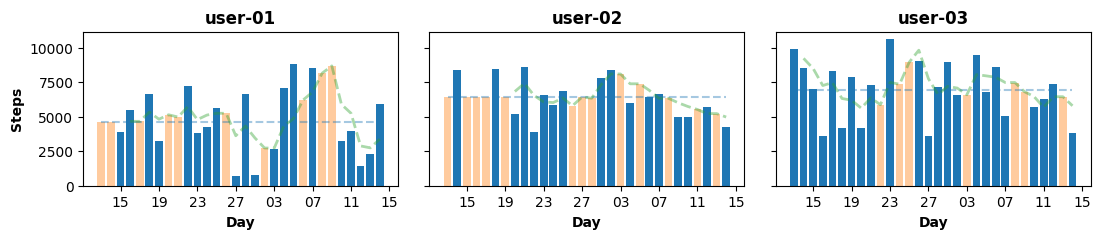

In [130]:
dataset["steps_rolling_mean"] = dataset.loc[:,["steps","user","date"]].groupby("user").rolling(on="date", min_periods=2, window=5)["steps"].mean().reset_index(drop=True)
dataset["steps_rolling_median"] = dataset.loc[:,["steps","user","date"]].groupby("user").rolling(on="date", min_periods=2, window=5)["steps"].median().reset_index(drop=True)

imputed_dataset = imputation.impute_missing_values_with_rolling_mean(
                                                    dataset = dataset, 
                                                    on = "steps",
                                                    id_col = "user",
                                                    date_col = "date",
                                                    rolling_min_periods = 2,
                                                    rolling_window = 5,
                                                )
fig, ax = plot_raw_steps_data(dataset=imputed_dataset, strategy="mean_rolling", plot_user_mean=True, plot_user_median=False)

If no imputation has to be forced, then we can set ``force_impute`` to ``False`` and so in all the days in which the rolling operation can't be performed, missing data will still be present.

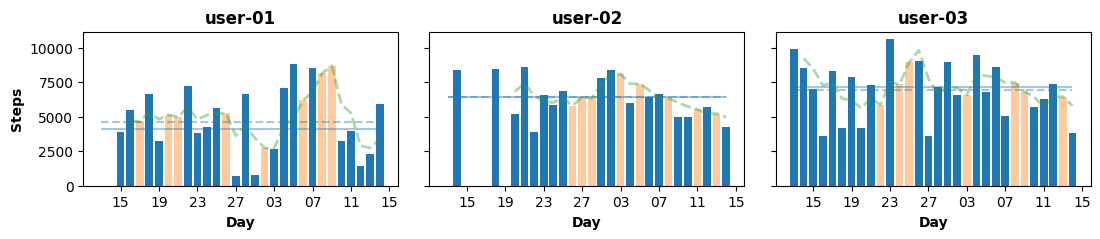

In [131]:
imputed_dataset = imputation.impute_missing_values_with_rolling_mean(
                                                    dataset=dataset, 
                                                    on="steps",
                                                    id_col = "user",
                                                    date_col= "date",
                                                    force_impute = False,
                                                    rolling_min_periods = 2,
                                                    rolling_window = 5,
                                                )
fig, ax = plot_raw_steps_data(dataset=imputed_dataset, strategy="mean_rolling")

## Rolling Median
Finally, we can perform imputation with a rolling operation using a median computation instead of the mean. 

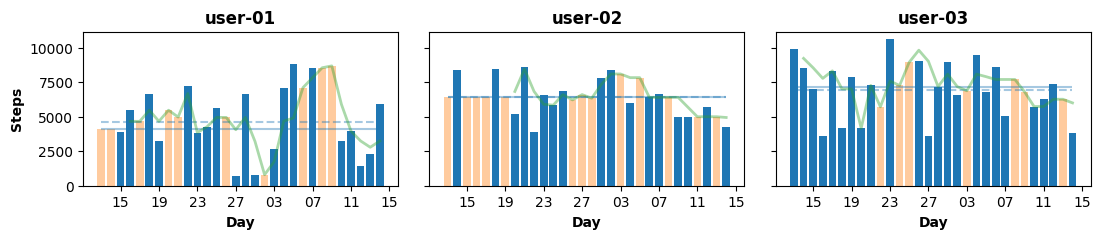

In [132]:
imputed_dataset = imputation.impute_missing_values_with_rolling_median(
                                                                        dataset = dataset, 
                                                                        on = "steps",
                                                                        id_col = "user",
                                                                        date_col = "date",
                                                                        force_impute = True,
                                                                        rolling_window = 5,
                                                                        rolling_min_periods = 2
                                                                    )
fig, ax = plot_raw_steps_data(dataset=imputed_dataset, strategy="median_rolling")